# E-Commerce Sales & Customer Analysis

This notebook analyzes the UCI Online Retail dataset using Python, Pandas, NumPy, and Matplotlib.

The workflow is designed to distinguish between:
- raw transactional data,
- net financial performance including returns/cancellations,
- product performance,
- customer performance.

This avoids overstating revenue by simply removing negative-quantity cancellation rows.

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

## 1. Load the raw dataset

In [54]:
df = pd.read_excel("../data/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [55]:
print("Shape:", df.shape)
print()
df.info()

Shape: (541909, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 2. Initial data quality checks

In [56]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDate range:")
display(df["InvoiceDate"].agg(["min", "max"]))

Missing values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Duplicate rows: 5268

Date range:


min   2010-12-01 08:26:00
max   2011-12-09 12:50:00
Name: InvoiceDate, dtype: datetime64[ns]

In [57]:
display(df[["Quantity", "UnitPrice"]].describe())

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


## 3. Inspect cancellations and suspicious records

Invoices beginning with `C` are cancellation invoices in this dataset.
Negative quantities therefore should not automatically be treated as bad data.

In [58]:
cancelled_rows = df[df["InvoiceNo"].astype(str).str.startswith("C")]

print("Cancelled rows:", len(cancelled_rows))
print("Unique cancelled invoices:", cancelled_rows["InvoiceNo"].nunique())

display(cancelled_rows.head(10))

Cancelled rows: 9288
Unique cancelled invoices: 3836


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [59]:
print("Top 20 rows by Quantity")
display(
    df.nlargest(20, "Quantity")[
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "UnitPrice", "CustomerID", "InvoiceDate"]
    ]
)

print("\nLargest negative quantities")
display(
    df.sort_values("Quantity").head(20)[
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "UnitPrice", "CustomerID", "InvoiceDate"]
    ]
)

Top 20 rows by Quantity


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,2011-11-25 15:57:00
74614,542504,37413,NaN,5568,0.00,NaN,2011-01-28 12:03:00
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901.0,2011-10-27 12:26:00
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,13135.0,2011-05-27 10:52:00
220843,556231,85123A,?,4000,0.00,NaN,2011-06-09 15:04:00
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,18087.0,2011-02-22 10:43:00
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,14609.0,2011-07-19 17:04:00
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0,2011-01-11 12:55:00



Largest negative quantities


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,2011-12-09 09:27:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,2011-01-18 10:17:00
225529,556690,23005,printing smudges/thrown away,-9600,0.00,NaN,2011-06-14 10:37:00
225530,556691,23005,printing smudges/thrown away,-9600,0.00,NaN,2011-06-14 10:37:00
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.03,15838.0,2010-12-02 14:23:00
225528,556687,23003,Printing smudges/thrown away,-9058,0.00,NaN,2011-06-14 10:36:00
115818,546152,72140F,throw away,-5368,0.00,NaN,2011-03-09 17:25:00
431381,573596,79323W,"Unsaleable, destroyed.",-4830,0.00,NaN,2011-10-31 15:17:00
341601,566768,16045,NaN,-3667,0.00,NaN,2011-09-14 17:53:00
323458,565304,16259,NaN,-3167,0.00,NaN,2011-09-02 12:18:00


Two extreme positive transactions in the dataset are later cancelled with matching negative quantities.
For this reason, the financial analysis below keeps both positive and negative quantities and calculates **net revenue**.

## 4. Build the net financial dataset

In [60]:
df_net = df.copy()

# Remove exact duplicate rows
df_net = df_net.drop_duplicates()

# Exclude zero or negative prices
# Negative quantities are intentionally retained because they represent returns/cancellations.
df_net = df_net[df_net["UnitPrice"] > 0].copy()

# Net line revenue
df_net["Revenue"] = df_net["Quantity"] * df_net["UnitPrice"]

# Date features
df_net["Year"] = df_net["InvoiceDate"].dt.year
df_net["Month"] = df_net["InvoiceDate"].dt.month
df_net["MonthName"] = df_net["InvoiceDate"].dt.month_name()
df_net["YearMonth"] = df_net["InvoiceDate"].dt.to_period("M")
df_net["DayOfWeek"] = df_net["InvoiceDate"].dt.day_name()
df_net["Hour"] = df_net["InvoiceDate"].dt.hour

df_net.shape

(534129, 15)

In [61]:
print("Net Revenue:", f"£{df_net['Revenue'].sum():,.2f}")

Net Revenue: £9,748,131.07


## 5. Cancellation metrics

In [62]:
total_unique_invoices_raw = df["InvoiceNo"].nunique()

cancelled_unique_invoices = (
    df[df["InvoiceNo"].astype(str).str.startswith("C")]["InvoiceNo"].nunique()
)

cancellation_rate = cancelled_unique_invoices / total_unique_invoices_raw * 100

print("Unique invoices in raw data:", total_unique_invoices_raw)
print("Unique cancellation invoices:", cancelled_unique_invoices)
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

Unique invoices in raw data: 25900
Unique cancellation invoices: 3836
Cancellation Rate: 14.81%


The cancellation rate above refers to the share of **unique invoices** in the raw dataset that are cancellation invoices.

## 6. Financial KPIs

In [63]:
net_revenue = df_net["Revenue"].sum()
net_orders = df_net["InvoiceNo"].nunique()

customer_df = df_net.dropna(subset=["CustomerID"]).copy()
customer_df["CustomerID"] = customer_df["CustomerID"].astype(int).astype(str)

total_customers = customer_df["CustomerID"].nunique()

# Net revenue by invoice, including negative cancellation invoices
gross_sales = df_net.loc[
    df_net["Quantity"] > 0,
    "Revenue"
].sum()

returns_value = abs(
    df_net.loc[
        df_net["Quantity"] < 0,
        "Revenue"
    ].sum()
)

net_revenue = df_net["Revenue"].sum()

print(f"Net Revenue: £{net_revenue:,.2f}")
print(f"Unique Invoices: {net_orders:,}")
print(f"Customers: {total_customers:,}")
print(f"Gross Sales: £{gross_sales:,.2f}")
print(f"Returns / Cancellations: £{returns_value:,.2f}")
print(f"Net Revenue: £{net_revenue:,.2f}")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

Net Revenue: £9,748,131.07
Unique Invoices: 23,796
Customers: 4,371
Gross Sales: £10,642,110.80
Returns / Cancellations: £893,979.73
Net Revenue: £9,748,131.07
Cancellation Rate: 14.81%


## 7. Monthly net revenue

In [64]:
monthly_net_revenue = (
    df_net
    .groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

monthly_net_revenue["YearMonth"] = monthly_net_revenue["YearMonth"].astype(str)

display(monthly_net_revenue)

,YearMonth,Revenue
0,2010-12,746723.610
1,2011-01,558448.560
2,2011-02,497026.410
3,2011-03,682013.980
4,2011-04,492367.841
5,2011-05,722094.100
6,2011-06,689977.230
7,2011-07,680156.991
8,2011-08,703510.580
9,2011-09,1017596.682


The raw dataset ends on 2011-12-09, so December 2011 is an incomplete month.
The main trend chart excludes that partial month.

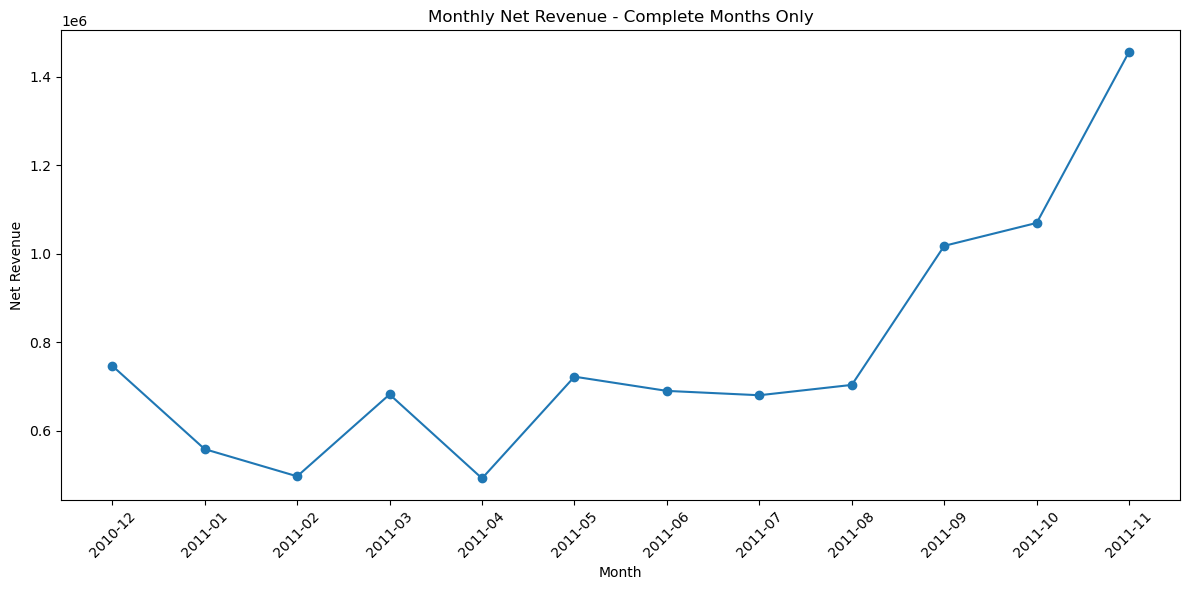

In [65]:
monthly_net_complete = monthly_net_revenue[
    monthly_net_revenue["YearMonth"] != "2011-12"
].copy()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_net_complete["YearMonth"],
    monthly_net_complete["Revenue"],
    marker="o"
)

plt.title("Monthly Net Revenue - Complete Months Only")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../images/monthly_net_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Product analysis

Administrative/non-product lines such as `POSTAGE`, `Manual`, and `Discount` are excluded from product ranking.
Returns and cancellations are still retained so products are ranked by **net product revenue**.

In [66]:
non_product_codes = [
    "POST",       # Postage
    "DOT",        # Dotcom postage
    "M",          # Manual adjustment
    "D",          # Discount
    "C2",         # Carriage
    "BANK CHARGES",
    "AMAZONFEE",
    "CRUK"
]

product_df = df_net[
    ~df_net["StockCode"]
    .astype(str)
    .isin(non_product_codes)
].copy()

top_products_net = (
    product_df
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_net

display(top_products_net)

Description
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
SPOTTY BUNTING                         42030.67
JUMBO BAG PINK POLKADOT                41584.43
Name: Revenue, dtype: float64

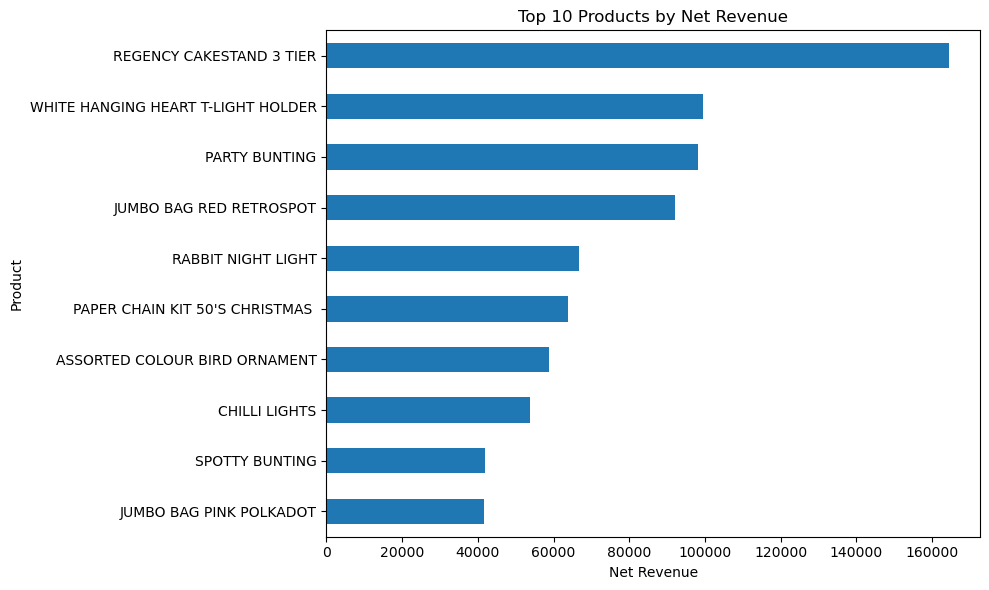

In [67]:
plt.figure(figsize=(10, 6))

top_products_net.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Net Revenue")
plt.xlabel("Net Revenue")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "../images/top_products_net_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [68]:
top_products_quantity_net = (
    product_df
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products_quantity_net)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47256
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35294
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26095
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64

## 9. Country analysis

In [69]:
country_net_revenue = (
    df_net
    .groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(country_net_revenue.head(10))

Country
United Kingdom    8189252.304
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: Revenue, dtype: float64

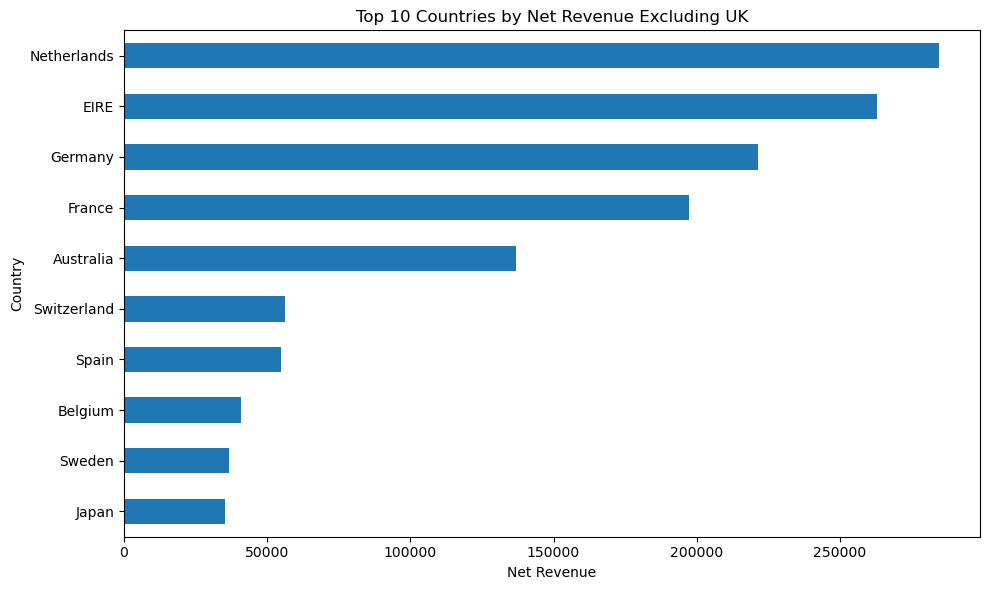

In [70]:
country_net_without_uk = (
    df_net[df_net["Country"] != "United Kingdom"]
    .groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

country_net_without_uk.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Net Revenue Excluding UK")
plt.xlabel("Net Revenue")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "../images/top_countries_net_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Customer analysis

In [71]:
customer_revenue = (
    customer_df
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(customer_revenue.head(10))

CustomerID
14646    279489.02
18102    256438.49
17450    187322.17
14911    132458.73
12415    123725.45
14156    113214.59
17511     88125.38
16684     65892.08
13694     62690.54
15311     59284.19
Name: Revenue, dtype: float64

In [72]:
customer_summary = (
    customer_df
    .groupby("CustomerID")
    .agg(
        NetRevenue=("Revenue", "sum"),
        UniqueInvoices=("InvoiceNo", "nunique"),
        NetQuantity=("Quantity", "sum")
    )
)

customer_summary["AverageRevenuePerInvoice"] = (
    customer_summary["NetRevenue"] / customer_summary["UniqueInvoices"]
)

display(
    customer_summary
    .sort_values("NetRevenue", ascending=False)
    .head(10)
)

,NetRevenue,UniqueInvoices,NetQuantity,AverageRevenuePerInvoice
CustomerID,,,,
14646,279489.02,76,196143,3677.487105
18102,256438.49,62,64122,4136.104677
17450,187322.17,55,69009,3405.857636
14911,132458.73,248,76905,534.107782
12415,123725.45,26,76946,4758.671154
14156,113214.59,66,56908,1715.372576
17511,88125.38,46,63012,1915.769130
16684,65892.08,31,49390,2125.550968
13694,62690.54,60,61899,1044.842333


## 11. Time-of-day analysis

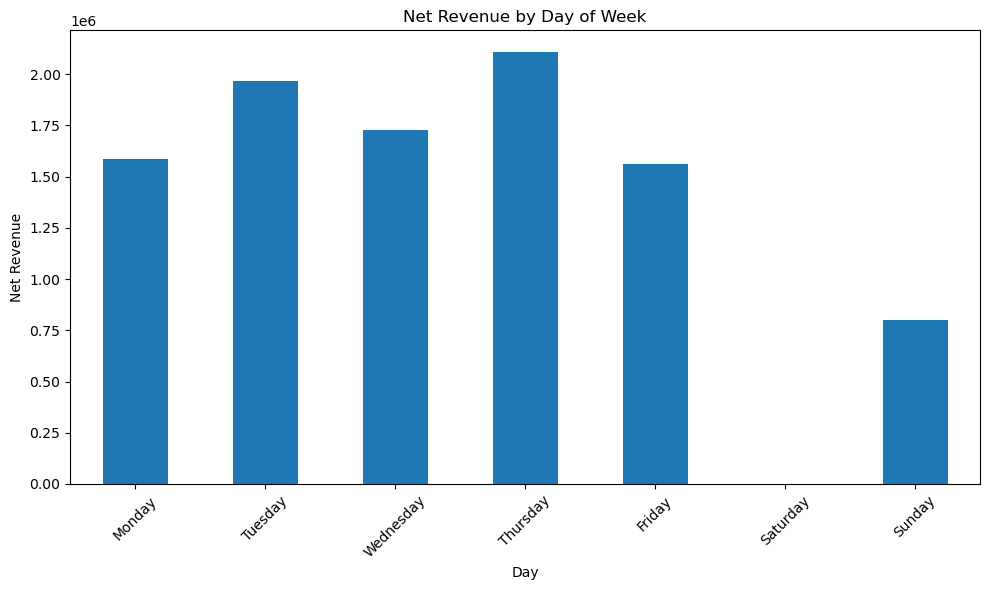

In [73]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_sales = (
    df_net
    .groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(day_order)
)

plt.figure(figsize=(10, 6))
day_sales.plot(kind="bar")

plt.title("Net Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Net Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

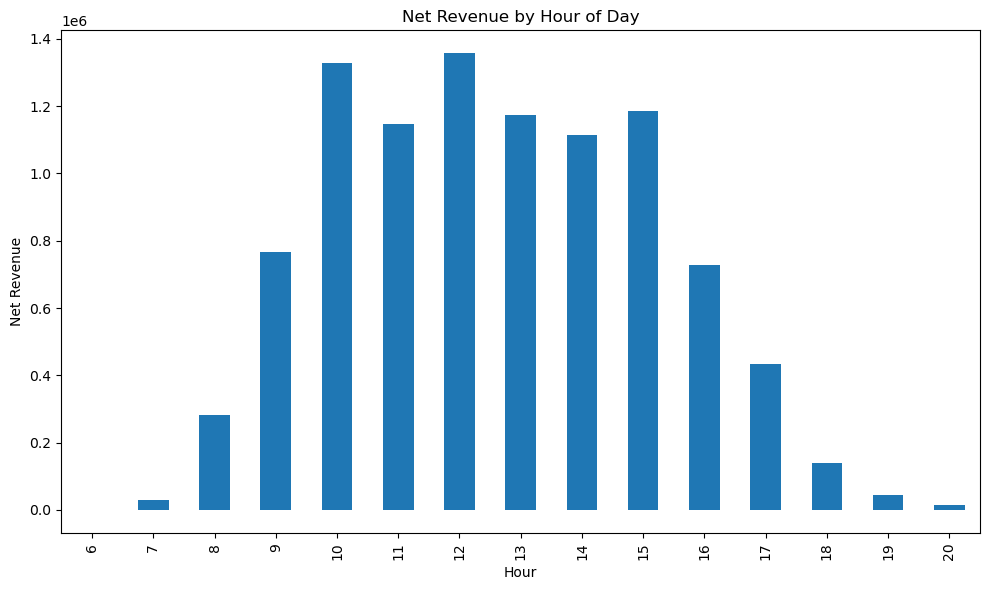

In [74]:
hourly_sales = df_net.groupby("Hour")["Revenue"].sum()

plt.figure(figsize=(10, 6))
hourly_sales.plot(kind="bar")

plt.title("Net Revenue by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Net Revenue")

plt.tight_layout()
plt.show()

## 12. Save cleaned analytical datasets

In [75]:
# Net financial dataset
df_net.to_csv(
    "../data/online_retail_net.csv",
    index=False
)

# Customer-focused dataset
customer_df.to_csv(
    "../data/online_retail_customer.csv",
    index=False
)

# Product-focused dataset
product_df.to_csv(
    "../data/online_retail_product.csv",
    index=False
)

print("Saved:")
print(os.path.abspath("../data/online_retail_net.csv"))
print(os.path.abspath("../data/online_retail_customer.csv"))
print(os.path.abspath("../data/online_retail_product.csv"))

Saved:
c:\Users\bahar\OneDrive\Desktop\ecommerce-sales-analysis\data\online_retail_net.csv
c:\Users\bahar\OneDrive\Desktop\ecommerce-sales-analysis\data\online_retail_customer.csv
c:\Users\bahar\OneDrive\Desktop\ecommerce-sales-analysis\data\online_retail_product.csv


## 13. Final validation

In [76]:
print("Exact duplicates in df_net:", df_net.duplicated().sum())
print("Rows with UnitPrice <= 0:", (df_net["UnitPrice"] <= 0).sum())
print("Missing CustomerID in customer_df:", customer_df["CustomerID"].isnull().sum())
print("Non-product codes remaining in product_df:",
      product_df["StockCode"].astype(str).isin(non_product_codes).sum())

Exact duplicates in df_net: 0
Rows with UnitPrice <= 0: 0
Missing CustomerID in customer_df: 0
Non-product codes remaining in product_df: 0


## 14. Project summary

In [77]:
print("PROJECT SUMMARY")
print("-" * 40)

print(f"Rows analyzed: {len(df_net):,}")
print(f"Gross Sales: £{gross_sales:,.2f}")
print(f"Returns / Cancellations: £{returns_value:,.2f}")
print(f"Net Revenue: £{net_revenue:,.2f}")
print(f"Unique Invoices: {net_orders:,}")
print(f"Customers: {total_customers:,}")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")
print(
    f"Data range: "
    f"{df_net['InvoiceDate'].min().date()} to "
    f"{df_net['InvoiceDate'].max().date()}"
)

PROJECT SUMMARY
----------------------------------------
Rows analyzed: 534,129
Gross Sales: £10,642,110.80
Returns / Cancellations: £893,979.73
Net Revenue: £9,748,131.07
Unique Invoices: 23,796
Customers: 4,371
Cancellation Rate: 14.81%
Data range: 2010-12-01 to 2011-12-09


## Key Business Insights

- November 2011 was the strongest complete month, generating approximately £1.46M in net revenue.
- Revenue increased substantially from September to November, indicating strong Q4 seasonality.
- December 2011 was excluded from full-month trend comparisons because the dataset ends on 9 December 2011.
- The Netherlands was the highest-revenue market outside the United Kingdom, followed by EIRE, Germany, France, and Australia.
- Regency Cakestand 3 Tier was the highest-revenue actual product after excluding administrative and non-product transaction codes.
- The highest-value customer was Customer 14646, generating approximately £279k in net revenue.
- Revenue was concentrated among a relatively small number of high-value customers.
- Returns and cancellations materially affected reported revenue. Retaining negative-quantity transactions was necessary to calculate accurate net revenue.